EJERCICIO 1:
DERIVACIÓN NUMÉRICA

In [1]:
#Este ejercicio busca que usted implemente correctamente dos métodos de derivación numérica: forward difference y central difference.
#Pruebe distintos valores de h (que equivale a distintos valores de M).

import numpy as np
import matplotlib.pylab as plt

# Función a derivar
def funcion(x1):
    	return np.cos(x1)


In [2]:
#El intervalo de integración es de 0 a 2pi.
#Divida el intervalo de integración en M secciones para calcular sus derivadas.
#pruebe distintos valores de M

# paso 1: use linespace (ver documentación: https://numpy.org/doc/stable/reference/generated/numpy.linspace.html)
# para hacer el arreglo de su intervalo en x
M=9999
a=0
b=2.0*np.pi

#paso 2: genere el arreglo de valores de su función fx:
x = np.linspace(a, b, M)
f_x = funcion(x)
h = (b - a) / (M - 1)

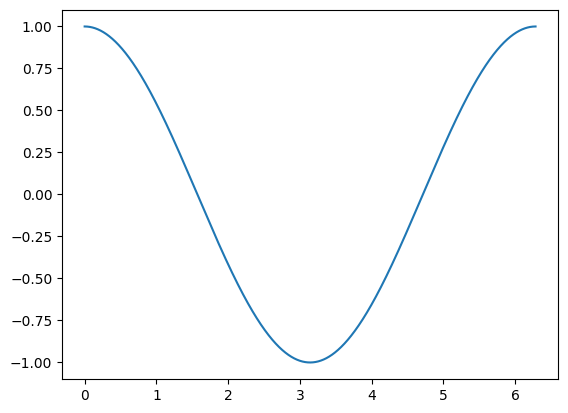

In [3]:
#1) grafique su función para verificar que hizo bien los pasos anteriores


import matplotlib.pyplot as plt

plt.plot(x,f_x)

plt.show()

In [4]:
# 2a). Implemente el algoritmo que le permita calcular la derivada de la función para los puntos en el intervalo 0 a 2pi usando forward difference.

der_f = np.zeros(M-1) #Creo un arreglo de tamaño M-1, pues el último punto no se puede calcular
error_f = np.zeros(M-1)
derivada_f = -np.sin(x[:-1]) # Creo el arreglo con la derivada anlítica de cos(x), siendo -sin(x)

der_f[:] = (f_x[1:] - f_x[:-1]) / h
error_f[:] = np.abs(derivada_f - der_f)

In [5]:
# 2b). Implemente el algoritmo que le permita calcular la derivada de la función para los puntos en el intervalo 0 a 2pi usando diferencia central.
der_c = np.zeros(M-2) # Creo un arreglo de tamaño M-2, pues ni el primer ni el último punto se pueden calcular
error_c = np.zeros(M-2)
derivada_c = -np.sin(x[1:-1]) # Creo el arreglo con la derivada de cos(x), siendo -sin(x)

der_c[:] = (f_x[2:] - f_x[:-2]) / (2*h)
error_c[:] = np.abs(derivada_c - der_c)

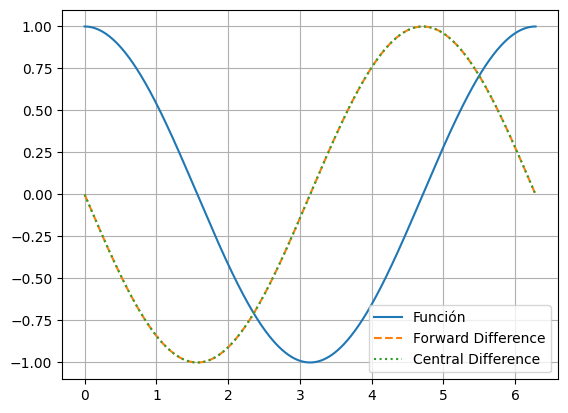

In [6]:
# 2c). Haga una gráfica de la función y sus derivadas obtenidas usando los dos métodos antes mencionados.

plt.plot(x, f_x, label="Función")
plt.plot(x[:-1], der_f, label="Forward Difference", linestyle="--")
plt.plot(x[1:-1], der_c, label="Central Difference", linestyle=":")
plt.legend()
plt.grid(True)
plt.show()

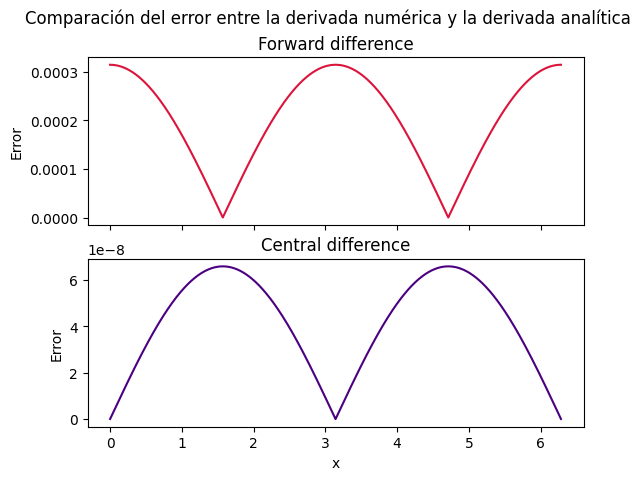

In [7]:
# 2d). Haga una grafica con dos subplots (uno por cada metodo) del error |(valor numérico - valor analitico)| en el intervalo.
fig, (ax1, ax2) = plt.subplots(2, sharex=True)

ax1.plot(x[:-1], error_f, color = "crimson")
ax1.set_ylabel("Error")
ax1.set_title("Forward difference")

ax2.plot(x[1:-1], error_c, color = "indigo")
ax2.set_xlabel("x")
ax2.set_ylabel("Error")
ax2.set_title("Central difference")

fig.suptitle("Comparación del error entre la derivada numérica y la derivada analítica")
plt.show()

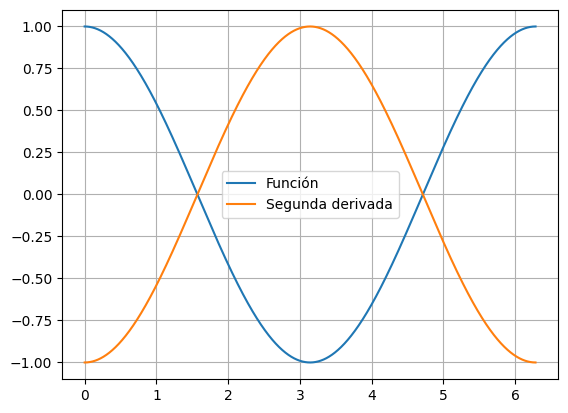

In [8]:
# 2e). Implemente el algoritmo que le permita calcular la segunda derivada de la función en el intervalo 0 a 2pi. Haga una gráfica de la función y su segunda derivada.

second_der = np.zeros(M-2) # Creo un arreglo de tamaño M-2, pues ni el primer ni el último punto se pueden calcular
second_der[:] = (f_x[2:] + f_x[:-2] - 2*f_x[1:-1]) / (h**2)

plt.plot(x, f_x, label="Función")
plt.plot(x[1:-1], second_der, label="Segunda derivada")
plt.legend()
plt.grid(True)
plt.show()

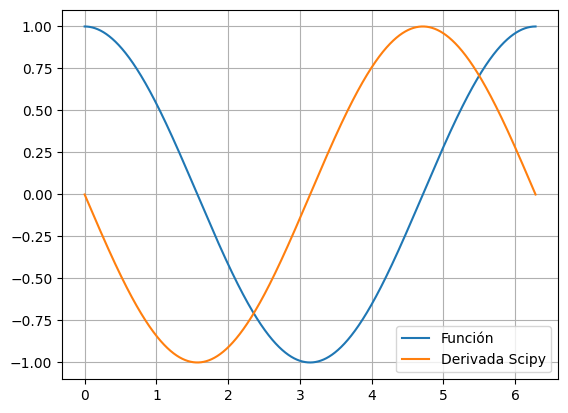

In [28]:
# 3) (opcional si terminan el ejercicio 2) Repita el ejercicio anterior usando algunos de los métodos de las librerías de scipy
# https://docs.scipy.org/doc/scipy/tutorial/integrate.html

from scipy import differentiate
sci_der = differentiate.derivative(funcion, x) # Obtiene varios datos de la derivada, para llamar los valores obtenitos se usa el atributo ".df"

plt.plot(x, f_x, label="Función")
plt.plot(x, sci_der.df, label="Derivada Scipy")
plt.title("Método Differentiate")
plt.legend()
plt.grid(True)
plt.show()

EJERCICIO 2: NEWTON-RAPHSON

In [10]:
# La idea de este ejercicio es que exploren la convergencia del método de Newton-Raphson para encontrar los ceros del siguiente polinomio:

def poli(x):
    	return  (x**5)-(1.7*x**4)-(10.0*x**3)+(20.0*x*x)+ (9.0*x)-18.0


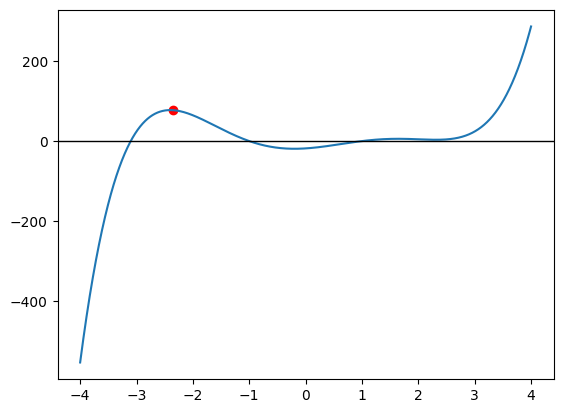

In [11]:
# Para esto:
# 1a.)  Haga una grafica del polinomio en el intervalo [-4:4].
N = 9999
c = -4
d = 4

x_NR = np.linspace(c, d, N)
h_NR = (d - c) / (N - 1)
f_NR = poli(x_NR)

plt.plot(x_NR, f_NR)
plt.scatter(-2.35, poli(-2.35), color = "red")
plt.axhline(color = "black", linewidth = 1)
plt.show()

In [12]:
# 1b.) Usando su implementación de Newton-Raphson, imprima el valor de una raíz x0_r del polinomio encontrada si usa como x_guess inicial el valor -2.35.
#Imprima el valor de x0_r encontrado y de f(x0_r)
x_guess = -2.35
f_x0 = 100

contador = 0
while np.abs(f_x0) > 1e-10:
  der_NR = (poli(x_guess + h_NR) - poli(x_guess - h_NR)) / (2*h_NR)
  delta_x = - poli(x_guess) / der_NR

  x_guess += delta_x
  f_x0 = poli(x_guess)

  contador += 1
  if contador == 100:
    break

print(f"El valor de x_0r es: {x_guess}, y el valor de f_x0r es: {f_x0}")

El valor de x_0r es: 0.9827328987557421, y el valor de f_x0r es: 1.5987211554602254e-13


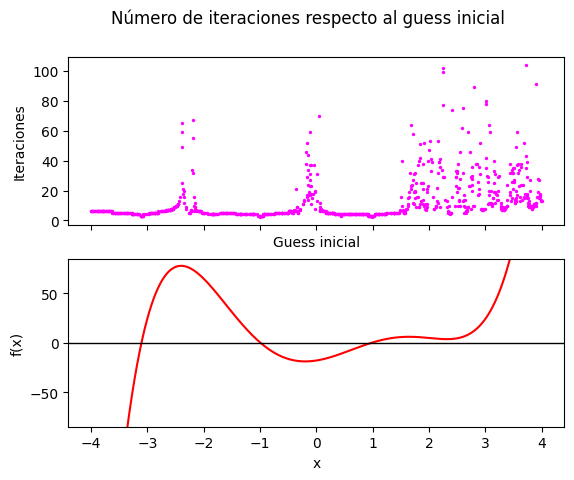

In [13]:
# 1c.) Repita lo anterior para 1000 valores de x_guess generados aleatoriamente en el intervalo [-4:4].
#Cuente cuantas iteraciones necesita su codigo para encontrar una raiz x_r del polinomio (tal que $f(x_r) sea menor a 10^{-10} para cada x_guess.
#Haga una grafica (use un scatter) del numero de iteraciones en funcion del x_guess inicial.
intentos = 1000

guesses = (np.random.rand(intentos) * 8) - 4
guesses_graph = np.copy(guesses)

iter = np.zeros(intentos)
raices = np.zeros(intentos)

for i in range(intentos):
  f_guess = 1000
  counter = 0
  while np.abs(f_guess) >= 1e-10:
    derivative = (poli(guesses[i] + h_NR) - poli(guesses[i] - h_NR)) / (2*h_NR)
    Delta_X = - poli(guesses[i]) / derivative

    guesses[i] += Delta_X
    f_guess = poli(guesses[i])

    counter += 1

  # Cuando termina el while se edita el array de ceros con el valor actual de "counter"
  iter[i] = counter


# print(guesses)
# print(iter)

fig, (ax1, ax2) = plt.subplots(2, sharex=True)

ax1.scatter(guesses_graph, iter, s = 2, color = "magenta")
ax1.set_xlabel("Guess inicial")
ax1.set_ylabel("Iteraciones")

ax2.plot(x_NR, f_NR, color = "red")
ax2.set_xlabel("x")
ax2.set_ylabel("f(x)")
ax2.set_ylim(-85,85)
ax2.axhline(color = "black", linewidth = 1)
fig.suptitle("Número de iteraciones respecto al guess inicial")
plt.show()

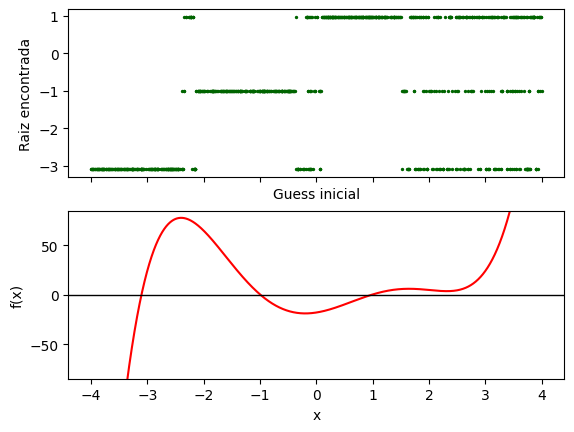

In [14]:
# 1c.) Haga una grafica (use un scatter) de la raíz encontrada (en el eje y) en función del x_guess inicial (en el eje x).

fig, (ax1, ax2) = plt.subplots(2, sharex=True)

ax1.scatter(guesses_graph, guesses, s = 2, color = "darkgreen")
ax1.set_xlabel("Guess inicial")
ax1.set_ylabel("Raiz encontrada")

ax2.plot(x_NR, f_NR, color = "red")
ax2.set_xlabel("x")
ax2.set_ylabel("f(x)")
ax2.set_ylim(-85,85)
ax2.axhline(color = "black", linewidth = 1)
plt.show()

In [15]:
# 1d.) Imprima un mensaje en donde explique por que cree que para ciertos valores de x_guess el numero de iteraciones necesarios para encontrar la raiz es mayor.
#Ademas haga un analisis y describa que pasa con los valores de x_r encontrados en esos puntos "problema" comprados con los encontrados para otros valores de x_guess.

print("""
El número de iteraciones mayor se puede explicar debido a que en esos puntos la derivada es practicamente cero,
por la construcción del método entonces la variación en X es bastante grande, y necesita de varios pasos extra
para conseguir llegar a una raíz.
Además, en estos valores la función tiende a encontrar distintas raices, debido a que un pequeño cambio en x
puede cambiar el signo de la derivada, donde puede buscar raices mayores o menores a ese x, además si la pendiente
es mayor o menor puede encontrar una raíz más alejada o más cercana respectivamente, logrando las
varias raices por valor de guesses similares.
Y para los guesses mayores a 1.5 puede que se obtengan distintas raices ya que la pendiente cae sobre un punto de
la función con derivada cero, lo que por cualquier pequeña variación logre llegar a cualquiera de las 3 raíces.
""")


El número de iteraciones mayor se puede explicar debido a que en esos puntos la derivada es practicamente cero,
por la construcción del método entonces la variación en X es bastante grande, y necesita de varios pasos extra
para conseguir llegar a una raíz.
Además, en estos valores la función tiende a encontrar distintas raices, debido a que un pequeño cambio en x
puede cambiar el signo de la derivada, donde puede buscar raices mayores o menores a ese x, además si la pendiente
es mayor o menor puede encontrar una raíz más alejada o más cercana respectivamente, logrando las
varias raices por valor de guesses similares.
Y para los guesses mayores a 1.5 puede que se obtengan distintas raices ya que la pendiente cae sobre un punto de
la función con derivada cero, lo que por cualquier pequeña variación logre llegar a cualquiera de las 3 raíces.

